In [1]:
import cv2
import sys
import numpy as np
import mediapipe as mp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml

import torch
import torch.nn as nn
import torch.optim as optim




In [2]:
# Configure MediaPipe
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

# Open video
video_path = "data/IMG_6705.mov"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"FPS: {fps}, Frames: {total_frames}")

SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


FPS: 29.998430778235036, Frames: 35366


In [7]:
# Process the video at a fixed stride. Every STEP-th frame is analysed.
STEP = 3
MAX_FRAMES = None   # e.g. 3000 to only process the first ~100 s
N_LM = 478          # MediaPipe Face Landmarker returns 478 points

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {video_path}")
fps = cap.get(cv2.CAP_PROP_FPS)

bs_rows, lm_rows, frame_ids = [], [], []
n_missing = 0

with FaceLandmarker.create_from_options(options) as landmarker:
    frame_idx = 0
    while True:
        if MAX_FRAMES is not None and frame_idx >= MAX_FRAMES:
            break
        if not cap.grab():
            break
        if frame_idx % STEP == 0:
            ok, frame = cap.retrieve()
            if not ok:
                break
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            result = landmarker.detect_for_video(mp_image, int(frame_idx / fps * 1000))

            if result.face_landmarks:
                lm = np.array([[p.x, p.y, p.z] for p in result.face_landmarks[0]])  # (478, 3)
                # Remove head position and distance-to-camera: centre and scale each frame
                lm = lm - lm.mean(axis=0)
                lm = lm / np.sqrt((lm ** 2).sum(axis=1).mean())
                bs = {c.category_name: c.score for c in result.face_blendshapes[0]} \
                     if result.face_blendshapes else {}
            else:
                lm = np.full((N_LM, 3), np.nan)   # keep a NaN row so time stays regular
                bs = {}
                n_missing += 1

            lm_rows.append(lm.reshape(-1))         # (1434,)
            bs_rows.append(bs)
            frame_ids.append(frame_idx)
        frame_idx += 1

cap.release()

df = pd.DataFrame(bs_rows)
df['frame_idx'] = frame_ids
LM = np.array(lm_rows)                             # (n_samples, 478*3)

print(f"Sampled {len(df)} frames, face missing in {n_missing}, landmark matrix {LM.shape}")
if df.empty:
    raise RuntimeError("No frames were processed - check video_path")

W0000 00:00:1795430064.049095  294834 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1795430064.056588  294837 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795430064.068570  294838 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Sampled 11789 frames, face missing in 5054, landmark matrix (11789, 1434)


In [8]:
display(df)

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight,frame_idx
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11784,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35352
11785,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35355
11786,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35358
11787,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35361


In [5]:
# df.to_csv("video_features.csv", index=False)

In [9]:
# --- Sliding windows over time; features = ALL landmarks of ALL frames in the window ---
WIN_SEC = 1.0
HOP_SEC = 0.5
samples_per_sec = fps / STEP
WIN = max(2, int(round(WIN_SEC * samples_per_sec)))
HOP = max(1, int(round(HOP_SEC * samples_per_sec)))

bs_cols = [c for c in df.columns if c != 'frame_idx']
missing = np.isnan(LM).all(axis=1)
LM_i = pd.DataFrame(LM).interpolate(limit_direction='both').fillna(0).to_numpy()
frames = df['frame_idx'].to_numpy()

feats, starts, ends, win_bs = [], [], [], []
for s in range(0, len(LM_i) - WIN + 1, HOP):
    if missing[s:s + WIN].mean() > 0.5:
        continue
    feats.append(LM_i[s:s + WIN].reshape(-1))            # WIN * 1434 values
    starts.append(frames[s])
    ends.append(frames[s + WIN - 1])
    win_bs.append(df[bs_cols].iloc[s:s + WIN].mean().fillna(0).to_numpy())

X_raw = np.array(feats)
X_bs_mean = np.array(win_bs)                             # kept only for the bar charts
win_df = pd.DataFrame({'start_frame': starts, 'end_frame': ends})
print(f"{len(win_df)} clips of {WIN} frames-samples, feature dim {X_raw.shape[1]}")

X_scaled = StandardScaler().fit_transform(X_raw)

pca = PCA(n_components=11)
X_pca = pca.fit_transform(X_scaled)

n_clusters = 5

1349 clips of 10 frames-samples, feature dim 14340


In [10]:
# 1. Definiera Autoencodern
class BlendshapeAutoencoder(nn.Module):
    def __init__(self, input_dim=52, latent_dim=10):
        super().__init__()
        # Encoder: Komprimerar 52 -> 32 -> latent_dim (t.ex. 10)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        # Decoder: Rekonstruerar tillbaka från latent_dim -> 32 -> 51
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# 2. Konvertera din skalade data till PyTorch-tensors
X_tensor = torch.FloatTensor(X_scaled)

# 3. Initiera modell, förlustfunktion och optimerare
input_dim = X_scaled.shape[1]
latent_dim = 2 # Motsvarar n_components=10 som du hade i PCA
model = BlendshapeAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Träna autoencodern (enkelt träningssteg)
epochs = 100
model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    reconstructions = model(X_tensor)
    loss = criterion(reconstructions, X_tensor)
    loss.backward()
    optimizer.step()

# 5. Extrahera det latenta rummet (ersätter X_pca)
model.eval()
with torch.no_grad():
    X_ae = model.encoder(X_tensor).numpy()

In [11]:
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

In [15]:
max_score = 0
sil_ae_array = np.zeros(11)
inertia_ae_array = np.zeros(11)
for k in range(2, 12):
    # Kör din logik för Autoencoder
    kmeans_ae = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_AE = kmeans_ae.fit_predict(X_ae)
    sil_ae = silhouette_score(X_ae, labels_AE)
    
    if sil_ae > max_score:
        max_score = sil_ae
        n_clusters = k
    
    sil_ae_array[k-1] = sil_ae
    inertia_ae_array[k-1] = kmeans_ae.inertia_

    # # Kör din logik för PCA
    # kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
    # labels_PCA = kmeans_pca.fit_predict(X_pca)
    # sil_pca = silhouette_score(X_pca, labels_PCA)

    # print(f"--- Antal kluster (k) = {k} ---")
    # print(f"Autoencoder -> Inertia: {kmeans_ae.inertia_:.2f} | Silhouette: {sil_ae:.3f}")
    # print(f"PCA         -> Inertia: {kmeans_pca.inertia_:.2f} | Silhouette: {sil_pca:.3f}\n")


print(f'Clusterss proposed: {n_clusters}')

# Change clusters based on elbow plot
n_clusters = 3
print(f'Clusters used: {n_clusters}')

kmeans = KMeans(n_clusters=n_clusters,random_state=SEED, n_init=10)

labels_AE = kmeans.fit_predict(X_ae)
labels_PCA = kmeans.fit_predict(X_pca)
labels_tsne = kmeans.fit_predict(X_tsne)

Clusterss proposed: 3
Clusters used: 3


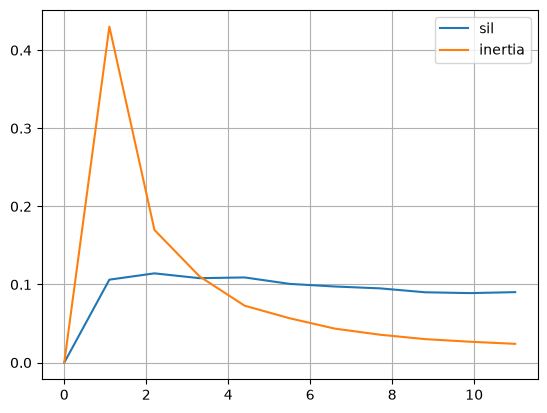

In [16]:
x = np.linspace(0,11,11)
plt.plot(x, sil_ae_array/np.sum(sil_ae_array), label="sil")
plt.plot(x, inertia_ae_array/np.sum(inertia_ae_array), label="inertia")
plt.legend()
plt.grid()
plt.show()

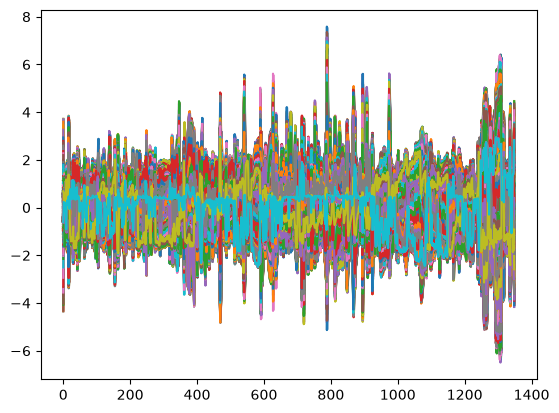

In [17]:
plt.plot(X_scaled)
plt.show()

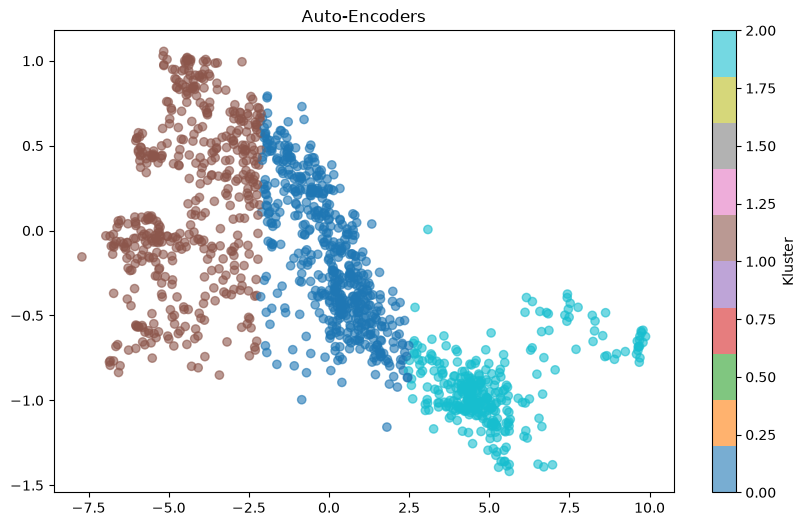

In [18]:
plt.figure(figsize=(10, 6))
plt.scatter(X_ae[:, 0], X_ae[:, 1], c=labels_AE, cmap='tab10', alpha=0.6)
plt.title("Auto-Encoders")
plt.colorbar(label='Kluster')
plt.show()

In [ ]:
import plotly.express as px

df_latent = pd.DataFrame(X_ae[:, :2], columns=['Latent 1', 'Latent 2'])
df_latent['Cluster'] = labels_AE.astype(str)
df_latent['start_frame'] = win_df['start_frame'].values
df_latent['time_s'] = (win_df['start_frame'].values / fps).round(2)

fig = px.scatter(
    df_latent, x='Latent 1', y='Latent 2', color='Cluster',
    hover_data=['start_frame', 'time_s'],
    title='Auto-Encoders (Latent Space, one dot = one clip)',
    opacity=0.6
)
fig.update_layout(xaxis_title='Latent 1', yaxis_title='Latent 2', template='plotly_white')
fig.show()

ModuleNotFoundError: No module named 'plotly'

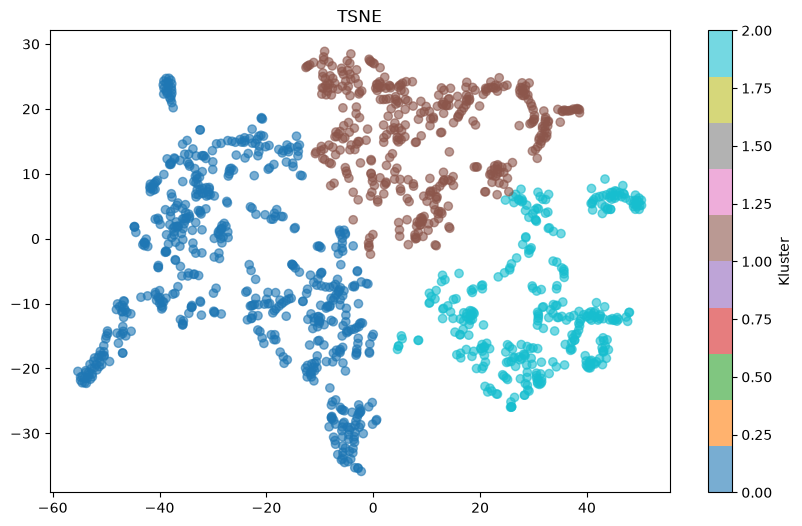

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_tsne, cmap='tab10', alpha=0.6)
plt.title("TSNE")
plt.colorbar(label='Kluster')
plt.show()

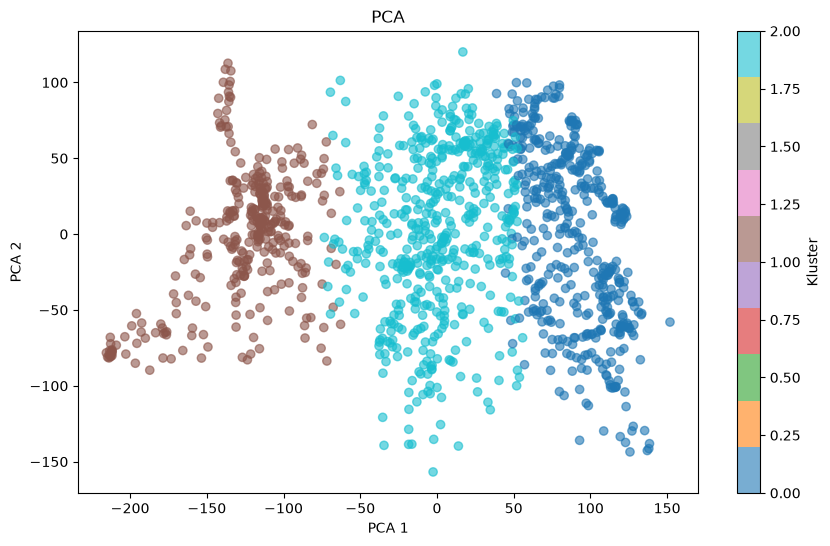

In [20]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_PCA, cmap='tab10', alpha=0.6)
plt.title("PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label='Kluster')
plt.show()

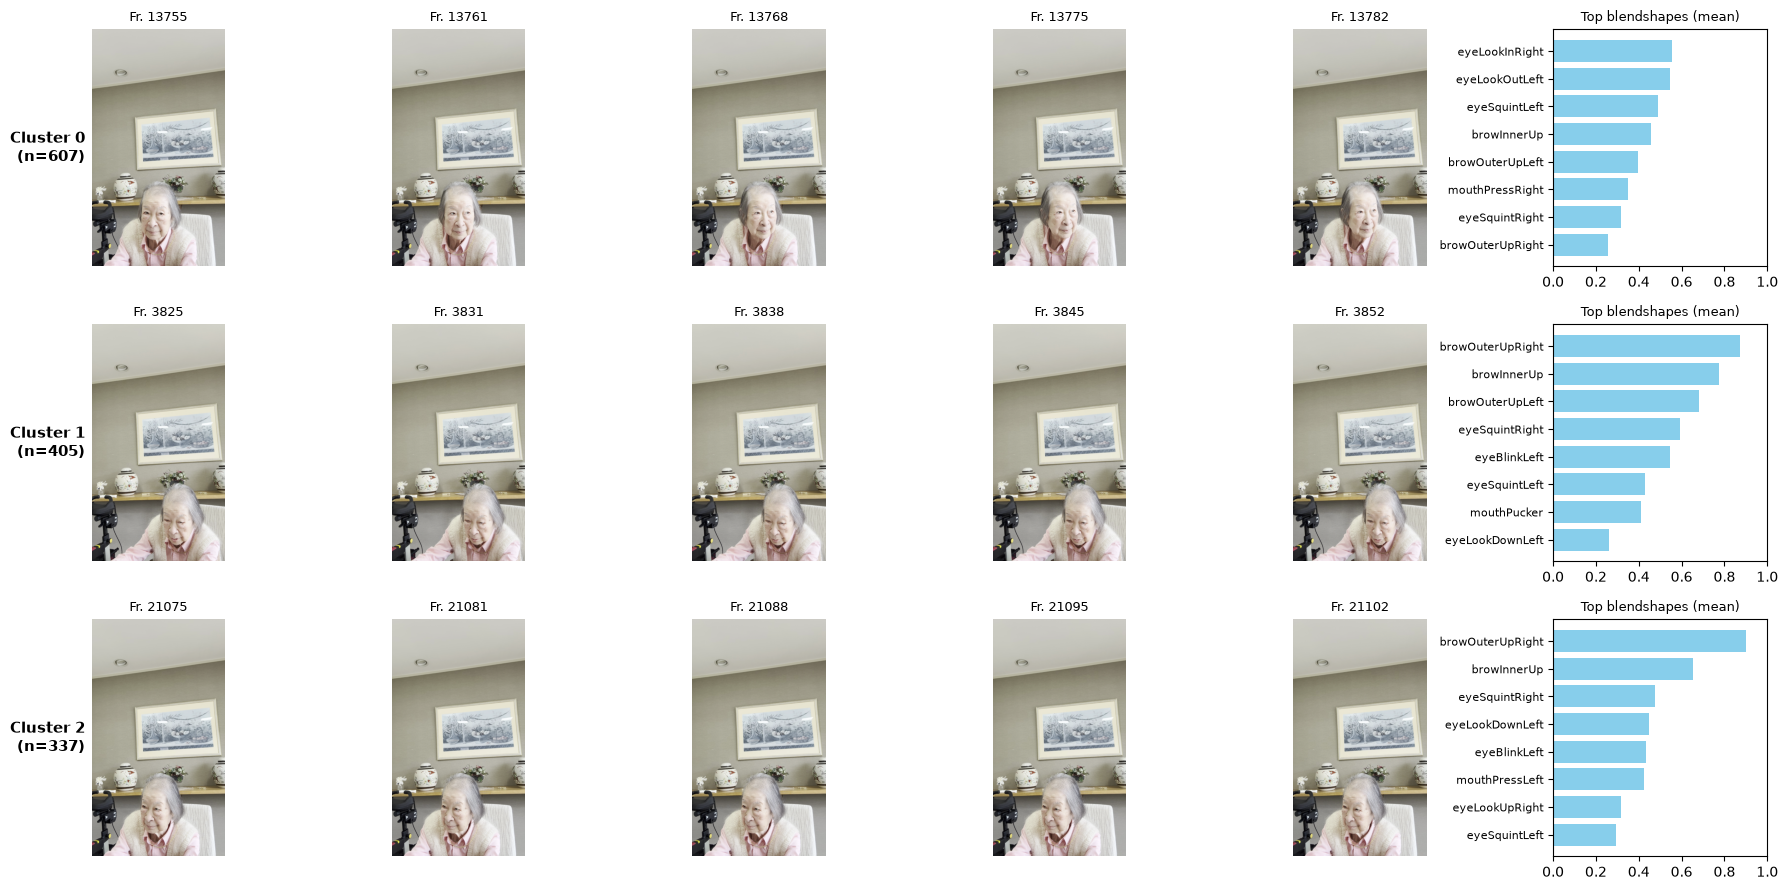

Saved example clips to ./clips/


In [21]:
import os

# Which embedding / labels to inspect (swap to X_ae/labels_AE or X_pca/labels_PCA)
SPACE, LABELS = X_tsne, labels_tsne

K_FRAMES = 5      # frames shown per clip (filmstrip)
N_CLIPS = 3       # mp4 clips saved per cluster
os.makedirs('clips', exist_ok=True)

def read_frames(path, start, end, k):
    cap_ = cv2.VideoCapture(path)
    out = []
    for i in np.linspace(start, end, k).astype(int):
        cap_.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, f = cap_.read()
        if ok:
            out.append((int(i), cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
    cap_.release()
    return out

def save_clip(path, start, end, out_path):
    cap_ = cv2.VideoCapture(path)
    cap_.set(cv2.CAP_PROP_POS_FRAMES, int(start))
    w = int(cap_.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap_.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    for _ in range(int(end - start) + 1):
        ok, f = cap_.read()
        if not ok:
            break
        writer.write(f)
    writer.release()
    cap_.release()

n_clusters = len(np.unique(LABELS))
fig, axes = plt.subplots(n_clusters, K_FRAMES + 1,
                         figsize=(3 * (K_FRAMES + 1), 3 * n_clusters), squeeze=False)

for c in range(n_clusters):
    idx = np.where(LABELS == c)[0]
    if len(idx) == 0:
        for a in axes[c]:
            a.axis('off')
        continue

    # clips closest to the cluster centroid = most "typical" clips
    d = np.linalg.norm(SPACE[idx] - SPACE[idx].mean(axis=0), axis=1)
    order = idx[np.argsort(d)]
    best = order[0]
    s, e = int(win_df.loc[best, 'start_frame']), int(win_df.loc[best, 'end_frame'])

    # filmstrip across the clip
    for j, (fi, img) in enumerate(read_frames(video_path, s, e, K_FRAMES)):
        axes[c, j].imshow(img)
        axes[c, j].axis('off')
        axes[c, j].set_title(f"Fr. {fi}", fontsize=9)
    axes[c, 0].text(-0.05, 0.5, f"Cluster {c}\n(n={len(idx)})", transform=axes[c, 0].transAxes,
                    ha='right', va='center', fontsize=11, fontweight='bold')

    # strongest average blendshapes over the clip
    top = pd.Series(X_bs_mean[best], index=bs_cols).nlargest(8)
    ax = axes[c, -1]
    ax.barh(np.arange(len(top)), top.values, color='skyblue')
    ax.set_yticks(np.arange(len(top)))
    ax.set_yticklabels(top.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title("Top blendshapes (mean)", fontsize=9)

    # save a few representative clips as mp4
    for j, g in enumerate(order[:N_CLIPS]):
        save_clip(video_path, win_df.loc[g, 'start_frame'], win_df.loc[g, 'end_frame'],
                  f"clips/cluster{c}_{j}.mp4")

plt.tight_layout()
plt.show()
print("Saved example clips to ./clips/")

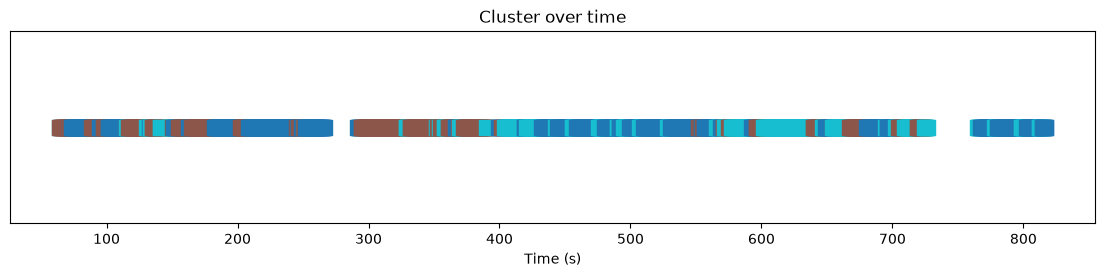

Wrote clustered_video.mp4


In [22]:
# 1) Cluster over time
centers = (win_df['start_frame'].to_numpy() + win_df['end_frame'].to_numpy()) / 2
plt.figure(figsize=(14, 2.5))
plt.scatter(centers / fps, np.zeros(len(centers)), c=LABELS, cmap='tab10', marker='s', s=120)
plt.yticks([])
plt.xlabel("Time (s)")
plt.title("Cluster over time")
plt.show()

# 2) Write the full video with the current cluster overlaid on every frame
cmap = plt.get_cmap('tab10')
cap_ = cv2.VideoCapture(video_path)
w = int(cap_.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap_.get(cv2.CAP_PROP_FRAME_HEIGHT))
writer = cv2.VideoWriter('clustered_video.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

last_frame = int(win_df['end_frame'].max())
f_idx = 0
while f_idx <= last_frame:
    ok, f = cap_.read()
    if not ok:
        break
    k = int(np.argmin(np.abs(centers - f_idx)))        # clip whose centre is nearest this frame
    r, g, b, _ = cmap(int(LABELS[k]) % 10)
    colour = (int(b * 255), int(g * 255), int(r * 255))  # BGR
    cv2.rectangle(f, (0, 0), (260, 60), (0, 0, 0), -1)
    cv2.putText(f, f"Cluster {LABELS[k]}", (10, 42), cv2.FONT_HERSHEY_SIMPLEX, 1.2, colour, 3)
    writer.write(f)
    f_idx += 1

writer.release()
cap_.release()
print("Wrote clustered_video.mp4")